# MP3 audio coding — worked example

This notebook illustrates **lossy audio compression** with MP3 by comparing an uncompressed PCM WAV recording with MP3 versions at different bitrates. It measures file sizes, listens to the decoded signals, and compares their time–frequency representations.

MP3 coding uses perceptual principles, including frequency masking, to allocate bits efficiently. The plots here show the **decoded audio**, not the internal MP3 filter bank or quantizer. A spectrogram alone does not demonstrate or measure perceptual masking.

## 1. Libraries and audio utilities

MP3 encoding/decoding uses **pydub** with **FFmpeg** installed on the system. For example, install `pydub` with `pip install pydub`; FFmpeg must also be accessible on your PATH.

Audio arrays are converted to floating-point values with a consistent range and correct handling of mono/stereo recordings. Plotting uses the actual sampling rate of each decoded signal.

In [1]:
from pathlib import Path
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from pydub import AudioSegment
from IPython.display import Audio, display


def to_float_audio(audio):
    """Return audio samples in [-1, 1] approximately, shape (samples, channels)."""
    samples = np.asarray(audio.get_array_of_samples())
    n_channels = audio.channels
    samples = samples.reshape(-1, n_channels)
    scale = float(1 << (8 * audio.sample_width - 1))
    return samples.astype(np.float64) / scale


def mono_view(samples):
    """Average the channels for visualization only (not for MP3 encoding)."""
    samples = np.asarray(samples)
    return samples.mean(axis=1) if samples.ndim == 2 else samples


def show_waveform(samples, fs, title, max_seconds=0.06):
    x = mono_view(samples)
    count = min(len(x), round(max_seconds * fs))
    t = np.arange(count) / fs
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.plot(t, x[:count], linewidth=0.8)
    ax.set(xlabel='Time (s)', ylabel='Amplitude', title=title)
    ax.grid(alpha=0.3)
    plt.show()


def show_spectrogram(samples, fs, title, vmin=-105, vmax=-20):
    x = mono_view(samples)
    nperseg = min(1024, len(x))
    freqs, times, S = signal.spectrogram(
        x, fs=fs, window='hann', nperseg=nperseg, noverlap=nperseg * 3 // 4,
        mode='magnitude', scaling='spectrum'
    )
    db = 20 * np.log10(np.maximum(S, 1e-12))
    fig, ax = plt.subplots(figsize=(10, 3.5))
    im = ax.pcolormesh(times, freqs, db, shading='auto', cmap='inferno', vmin=vmin, vmax=vmax)
    ax.set(xlabel='Time (s)', ylabel='Frequency (Hz)', title=title, ylim=(0, min(fs / 2, 10000)))
    fig.colorbar(im, ax=ax, label='Magnitude (dB, relative to digital full scale)')
    plt.show()


## 2. Load a WAV sound

The example uses `../sounds/synthetic.wav` when available. Otherwise it creates a deterministic five-second harmonic sound with a changing pitch and gentle amplitude modulation. Using the synthetic fallback means the example runs without course audio files.

The fallback is exported as a **16-bit PCM WAV** so that the WAV-vs-MP3 file-size comparison is meaningful.

Using course recording: ../sounds/synthetic.wav
Original: 3.00 s, 44100 Hz, 1 channel(s)
WAV size: 264,644 bytes


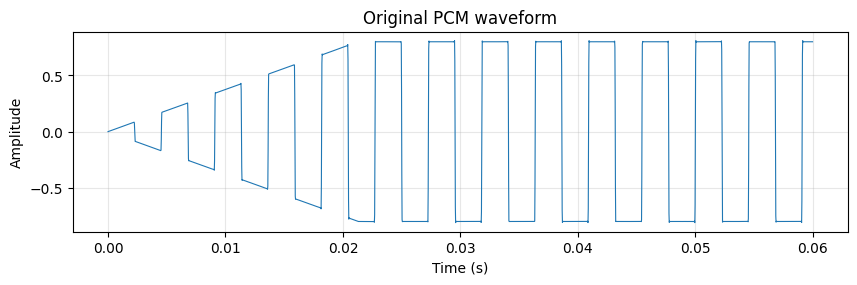

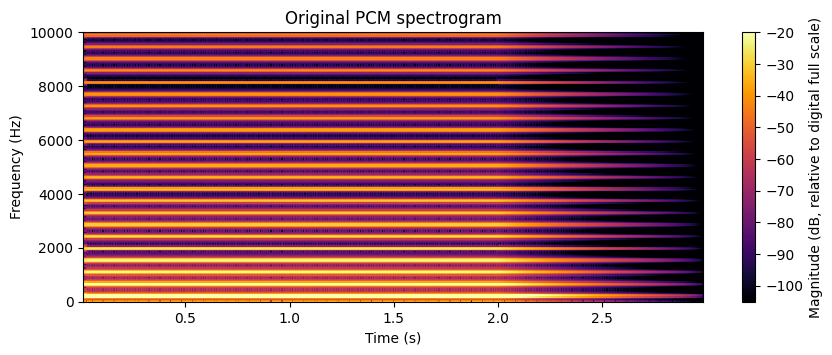

Original audio:


In [2]:
source_path = Path('../sounds/synthetic.wav')
if source_path.exists():
    original = AudioSegment.from_wav(str(source_path))
    print(f'Using course recording: {source_path}')
else:
    fs = 44100
    duration_s = 5.0
    t = np.arange(int(fs * duration_s)) / fs
    phase = 2 * np.pi * (220 * t + (660 - 220) * t**2 / (2 * duration_s))
    x = (np.sin(phase) + 0.35 * np.sin(2 * phase) + 0.2 * np.sin(3 * phase))
    x *= 0.40 * (0.75 + 0.25 * np.cos(2 * np.pi * 2 * t))
    x16 = np.round(np.clip(x, -1, 1) * 32767).astype('<i2')
    original = AudioSegment(data=x16.tobytes(), sample_width=2, frame_rate=fs, channels=1)
    print('Course WAV not found; using a reproducible synthetic harmonic signal.')

# Create an uncompressed WAV as the common baseline for file-size comparison.
wav_buffer = BytesIO()
original.export(wav_buffer, format='wav')
wav_bytes = wav_buffer.getvalue()
original_samples = to_float_audio(original)
fs = original.frame_rate
print(f'Original: {len(original_samples)/fs:.2f} s, {fs} Hz, {original.channels} channel(s)')
print(f'WAV size: {len(wav_bytes):,} bytes')
show_waveform(original_samples, fs, 'Original PCM waveform')
show_spectrogram(original_samples, fs, 'Original PCM spectrogram')
print('Original audio:')
display(Audio(original_samples.T, rate=fs, normalize=False))


## 3. Encode and decode MP3 at different bitrates

`bitrate` controls the approximate number of bits per second used in the compressed stream. Lower bitrates usually mean smaller files and potentially greater audible distortion. The exact relationship depends on channel count, encoder settings, codec overhead, and source content.

Decoded MP3 samples are **not expected to equal** the original PCM samples: MP3 is a lossy codec. Encoders may also introduce a small leading delay or padding, which makes sample-by-sample subtraction misleading without alignment.

In [3]:
bitrates = ['256k', '192k', '96k', '32k']
encoded = {}
for bitrate in bitrates:
    buffer = BytesIO()
    original.export(buffer, format='mp3', bitrate=bitrate)
    mp3_data = buffer.getvalue()
    decoded = AudioSegment.from_file(BytesIO(mp3_data), format='mp3')
    encoded[bitrate] = {'bytes': mp3_data, 'decoded': decoded,
                        'samples': to_float_audio(decoded)}
    size_kib = len(mp3_data) / 1024
    ratio = len(wav_bytes) / len(mp3_data)
    print(f'{bitrate:>4}: {size_kib:8.1f} KiB; WAV/MP3 size ratio = {ratio:.2f}:1; '
          f'decoded duration = {len(decoded)/1000:.3f} s')


256k:     95.6 KiB; WAV/MP3 size ratio = 2.70:1; decoded duration = 3.000 s
192k:     71.7 KiB; WAV/MP3 size ratio = 3.61:1; decoded duration = 3.000 s
 96k:     35.9 KiB; WAV/MP3 size ratio = 7.21:1; decoded duration = 3.000 s
 32k:     12.1 KiB; WAV/MP3 size ratio = 21.43:1; decoded duration = 3.000 s


## 4. Listen to the decoded sounds

Use the same playback gain for all sounds: `normalize=False` prevents the audio widget from independently rescaling each example. Notice that differences may be subtle, especially at high bitrates. Playback quality depends on the listening equipment and source material.

In [4]:
print('Original WAV')
display(Audio(original_samples.T, rate=fs, normalize=False))
for bitrate in bitrates:
    decoded = encoded[bitrate]['decoded']
    samples = encoded[bitrate]['samples']
    print(f'MP3 decoded at {bitrate}')
    display(Audio(samples.T, rate=decoded.frame_rate, normalize=False))


Original WAV


MP3 decoded at 256k


MP3 decoded at 192k


MP3 decoded at 96k


MP3 decoded at 32k


## 5. Compare file sizes and spectra

The displayed spectrograms are produced by **decoding each MP3 back to PCM**. They can reveal changes such as the loss of high-frequency components at low bitrates, but they do not by themselves determine perceived audio quality. All panels use the same decibel color limits.

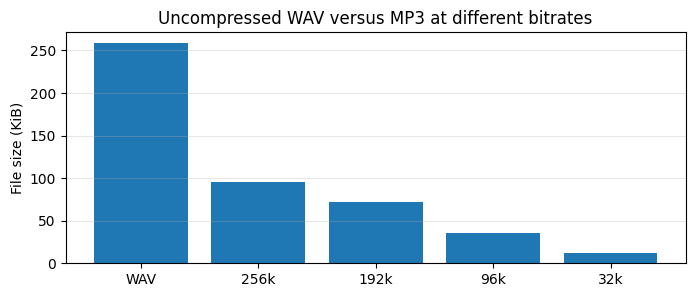

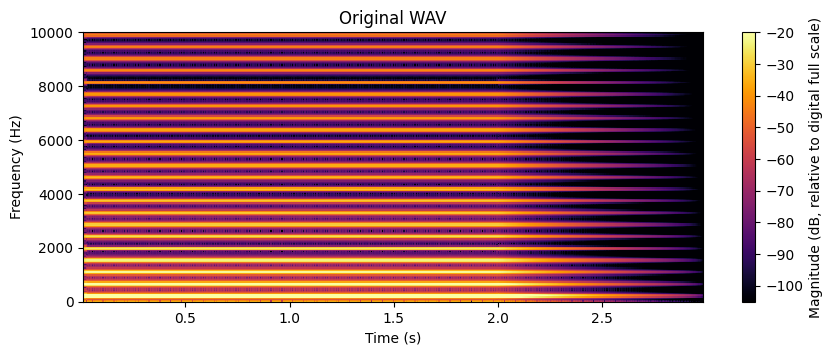

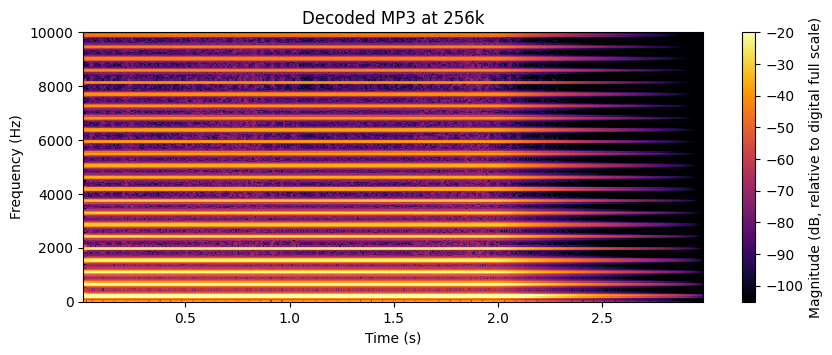

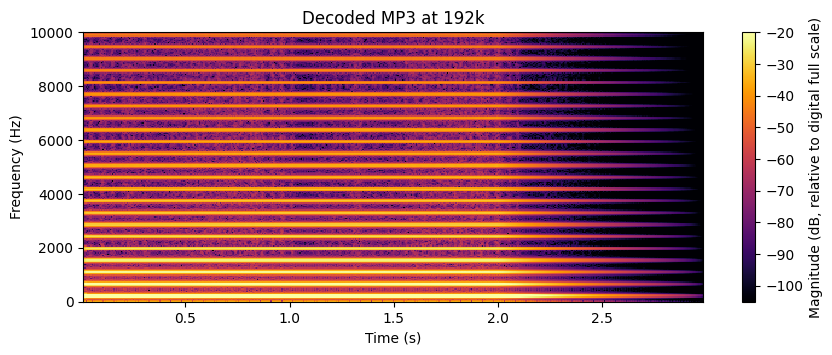

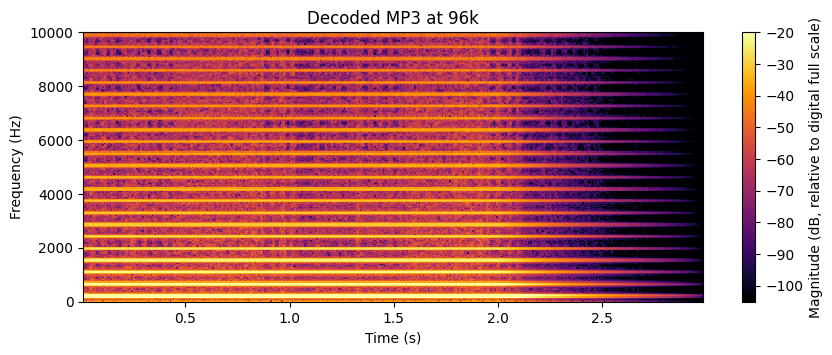

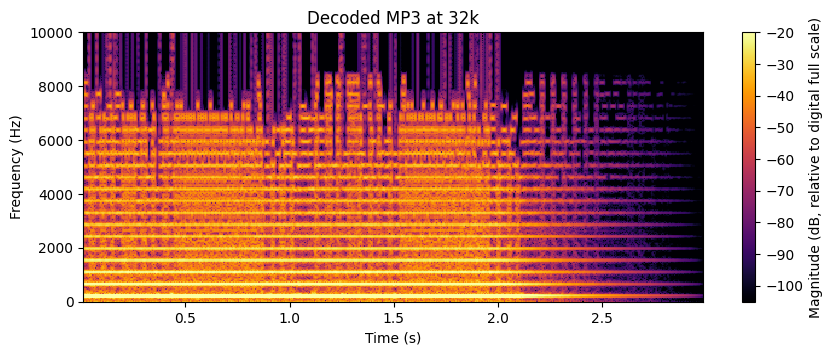

In [5]:
labels = ['WAV'] + bitrates
sizes = [len(wav_bytes)] + [len(encoded[b]['bytes']) for b in bitrates]
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(labels, np.array(sizes) / 1024)
ax.set(ylabel='File size (KiB)', title='Uncompressed WAV versus MP3 at different bitrates')
ax.grid(axis='y', alpha=0.3)
plt.show()

show_spectrogram(original_samples, fs, 'Original WAV')
for bitrate in bitrates:
    item = encoded[bitrate]
    show_spectrogram(item['samples'], item['decoded'].frame_rate,
                     f'Decoded MP3 at {bitrate}')


## 6. What to remember

- MP3 is **lossy perceptual audio coding**: decoding restores a playable waveform but not necessarily the original samples.
- Reducing the target bitrate generally decreases file size and can increase audible artifacts.
- File-size comparisons must account for the original WAV's bit depth, channels, and duration, as well as codec overhead.
- A decoded-signal spectrogram illustrates changes to the audio spectrum, **not** the internal MP3 transform, psychoacoustic model, or bit allocation.
- The relationship between spectral changes and perceived quality depends on masking, listening level, playback equipment, and program material.

**Technical note:** MP3 uses a hybrid filter bank (polyphase analysis and MDCT), quantization, psychoacoustic bit allocation, and entropy coding. This notebook demonstrates the codec as a whole rather than implementing those stages.